# Beyond Linearity — multi-config sweep

Generalization of `beyondlinearity_V3.ipynb` to run the Schur-complement
rank / nu_frac analysis across every checkpoint config Pietro shared, instead
of just one `linear` vs one `nonlinear` checkpoint.

Everything in "Model definition" and "Stats functions" is copy-pasted
unmodified from V3 (the fixed-hook version). Only the checkpoint
download/load and the analysis loop are new — generalized to iterate over
a config table instead of two hardcoded checkpoints.

In [1]:
import numpy as np
import torch
import torch.nn as nn
from dataclasses import dataclass
from typing import Callable, Optional
import matplotlib.pyplot as plt
import math
np.random.seed(0)
torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

c:\Users\dunli\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


device: cuda


## Config table

One row per checkpoint folder from the shared Drive. `query_mode` is parsed from the folder name (`original` vs `residual_gelu` — those are the only two families present). `mlp_mult` defaults to 4.0 (standard GPT-2 ratio) and is overridden only for the explicit `mlp_4_X_times` configs, since architecture (not just training hyperparams) differs there and must be reflected in `mlp_hidden_size` or the state_dict won't load.

In [2]:
CONFIGS = [
    # name,                                                     file_id,                              filename,          query_mode,       mlp_mult
    ("tiedw_original",                                          "1zsdK2tTfrzuE5jL9p8YWaCah7uX-4x8f", "ckpt_50000.pt", "original",        4.0),
    ("tiedw_original_005wd",                                    "1QEvEm55vKEIyhaq755oaZkpF3CJ-cf36", "ckpt.pt",       "original",        4.0),
    ("tiedw_original_20k_steps",                                "1f1LungSE884IOAtWH_xGgjUCijN8zQhd", "ckpt.pt",       "original",        4.0),
    ("tiedw_original_mlp_4_33_times",                           "1AyERlOwh6N2-qRigz2mhQCUQK05MTLXX", "ckpt_50000.pt", "original",        4.33),
    ("tiedw_original_mlp_4_5_times",                            "1OICQqm3p4uMKl36MzJpJS4ibeCweNFPx", "ckpt_50000.pt", "original",        4.5),
    ("tiedw_original_mlp_4_625_times",                          "13UnT0Xao3bJpbop6QUPJ1b_7NqTErjAQ", "ckpt_50000.pt", "original",        4.625),
    ("tiedw_original_mlp_4_75_times",                           "1IHJgnjzqB1kQMw5am9IAYhPGHZF70qR5", "ckpt_50000.pt", "original",        4.75),
    ("tiedw_original_mlp_4_75_times_lrscaled",                  "1VLv1YtvnHRq2-xKecAwJWFSq-aiOzbZP", "ckpt_50000.pt", "original",        4.75),
    ("tiedw_residual_gelu",                                     "1kRUJiXm7-mxr8txJ3sWdAzHLGw9Pa7gm", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_0025wd_1_7e-3lr_3e-5",                "1_0FMdqQACLDr_Aavd0SxSVEICC8cCJKX", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_0025wd_2_4e-3lr_3e-5",                "1L55677VBCR_cGo-cq66uDAKTpC5aiDA1", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_005wd",                               "1DlrXR53C6X4WugIt6kl9ZQTp8YbGceiB", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_005wd_1_1e-3lr",                      "103wVUEOynWF--xg8pWnCklOWeGNXyqAf", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_005wd_2_4e-3lr_3e-5",                 "1yLbeGlGV4MMeylMZaagx4QF8XrG7BW-C", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_01wd_3_6e-3lr_2e-5",                  "1o_MzM-0nusruaMsDDJGGdP6LipQOGrL0", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_01wd_3_6e-3lr_2e-5_20k_steps",        "123ArBFJMAFQpg3kuYtCJ57dYskGJGX9F", "ckpt.pt",       "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_1_2e-3lr",                      "15EvEKSXjF57gLJ96ztRVxo9mIqefE8E9", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_1_2e-3lr_3e-4",                 "1UqszdKOJ0Dxg-XJIfcpa6GZ3-AL6yqU2", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_1_2e-3lr_7e-5",                 "1kxjbf9vumvfqLWD9W-AX4kG3ej3oVhcj", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_1_5e-3lr_4e-5",                 "1FIUIQ10qhkKWG1y_invJwsyScWa9XA9S", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_1_7e-3lr_3e-5",                 "1DrSl7NVvbY8x4YVfviiOJqASPWRGCmWz", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_1_7e-3lr_5e-5",                 "1XRaozWknrJGfX9isz5aPzdsWAYXHFASS", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_2_2e-3lr_3e-5",                 "1aAAsT6fdTHoq8sJNiLa1YSbNWb-CU52u", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_2_4e-3lr_3e-5",                 "1cKetR9qFTdtI3YPGmwz33mUfYYMP-oj1", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_2_6e-3lr_3e-5",                 "1TgcEQzEytDEWKhna9tviYRfMEHtJVCza", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_2_8e-3lr_3e-5",                 "1i4CCJqhp10WCaX8MMYaUg8sBdy-TNV46", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_2e-3lr_3e-5",                   "1mTZECjLIa5uZi5aLwBM0po6g1owfti7_", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_3_2e-3lr_3e-5",                 "15xCX7wFmFOaZHy5g7bC96wKgpDDmc5_p", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_3_4e-3lr_3e-5",                 "1wuA1J6MHzTcy03Fs-gRl7XeQ8KepgZ5R", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-5wd_3e-3lr_3e-5",                   "1z4WOZJuSlkIBg8t0RpW2XYH0g_gS3pKf", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-6wd_1_5e-3lr_4e-5",                 "1gvTXZdgT_Sc4QTPEXeN8EORhtASr3UT3", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-6wd_1_5e-3lr_8e-5",                 "1SJkUQw9BS9JjoKbLfuMtdjysxLG_yW_-", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-6wd_2e-3lr_1_2e-4",                 "1YzsraoUH_KkpWvi-z--nogcinRgyEoKI", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-6wd_2e-3lr_2e-5",                   "1TanpzODcJPRCF9PBMxWK0SotVs4cx8tf", "ckpt_50000.pt", "residual_gelu",   4.0),
    ("tiedw_residual_gelu_2-6wd_2e-3lr_8e-5",                   "1SqcMOk_9nJvmNdB2k3KSJzSVbk2afR6S", "ckpt_50000.pt", "residual_gelu",   4.0),
]

print(f"{len(CONFIGS)} configs queued")

35 configs queued


## Download all checkpoints

Skips any file already downloaded, so re-running a cell after a partial run / disconnect doesn't re-fetch everything.

In [3]:
# Already downloaded -- skipping re-download. Keeping CKPT_DIR / os since
# load_model_from_config (cell below) still needs to find the files on disk.
import os

CKPT_DIR = r"D:\modification research\checkpoint"

# --- download logic disabled, checkpoints already present locally ---
# os.makedirs(CKPT_DIR, exist_ok=True)
#
# MIN_VALID_SIZE_BYTES = 10_000  # a real ckpt is tens/hundreds of MB; anything this small is
#                                  # almost certainly gdown's HTML "quota exceeded" error page,
#                                  # not the actual file -- catches silent partial-download failures.
#
# for name, file_id, filename, query_mode, mlp_mult in CONFIGS:
#     dest = os.path.join(CKPT_DIR, f"{name}.pt")
#     if os.path.exists(dest) and os.path.getsize(dest) > MIN_VALID_SIZE_BYTES:
#         continue
#     print(f"downloading {name} ...")
#     !gdown "{file_id}" -O "{dest}" -q
#     if not os.path.exists(dest) or os.path.getsize(dest) < MIN_VALID_SIZE_BYTES:
#         print(f"  !! FAILED or suspiciously small: {name} (file_id={file_id})")
#         failed_downloads.append(name)
#
# if failed_downloads:
#     print(f"\n{len(failed_downloads)} downloads failed/suspicious, will be skipped in the sweep:")
#     for n in failed_downloads:
#         print(f"  - {n}")
#     print("Re-run this cell later to retry them (successful downloads are cached and skipped).")
# else:
#     print("\nall downloads OK")

failed_downloads = []  # kept defined since cell 17 references it


## Model definition

Unmodified from V3 — `CausalSelfAttention`, `MLP`, `Block`, `GPTConfig`, `GPT`.

In [4]:
""" TAKEN FRON THE karpathy/nanogpt repository with modifications at the Query.
Full definition of a GPT Language Model, all of it in this single file.
References:
1) the official GPT-2 TensorFlow implementation released by OpenAI:
https://github.com/openai/gpt-2/blob/master/src/model.py
2) huggingface/transformers PyTorch implementation:
https://github.com/huggingface/transformers/blob/main/src/transformers/models/gpt2/modeling_gpt2.py
"""

import math
import inspect
from dataclasses import dataclass

import torch
import torch.nn as nn
from torch.nn import functional as F

class LayerNorm(nn.Module):
    """ LayerNorm but with an optional bias. PyTorch doesn't support simply bias=False """

    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None

    def forward(self, input):
        return F.layer_norm(input, self.weight.shape, self.weight, self.bias, 1e-5)

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.num_heads == 0
        self.config = config
        # key, query, value projections for all heads, but in a batch
        if self.config.query_mode in ["identity", "residual_gelu"]:
            # reduced GPT-2 style, as per our paper
            # so we only have 2 * n_embd weights in total, instead of 3 * n_embd
            self.c_attn = nn.Linear(config.n_embd, 2 * config.n_embd, bias=config.bias)
        elif self.config.query_mode in ["residual", "original"]:
            # original query weights, with modifications on the application
            self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        # regularization
        if self.config.query_mode == "residual_gelu":
            self.residual_rmsnorm_input = nn.RMSNorm(config.n_embd, eps=1e-5)
            self.residual_layernorm_output = LayerNorm(config.n_embd, bias=config.bias)
            self.residual_in = nn.Linear(config.n_embd, config.n_embd//2, bias=config.bias)
            self.residual_out = nn.Linear(config.n_embd//2, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.num_heads = config.num_heads
        self.n_embd = config.n_embd
        self.dropout = config.dropout
        self.mlp_hidden_size = config.mlp_hidden_size
        # flash attention make GPU go brrrrr but support is only in PyTorch >= 2.0
        self.flash = hasattr(torch.nn.functional, 'scaled_dot_product_attention')
        self.config = config
        if not self.flash:
            print("WARNING: using slow attention. Flash Attention requires PyTorch >= 2.0")
            # causal mask to ensure that attention is only applied to the left in the input sequence
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                        .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)

        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        if self.config.query_mode in ["identity","residual_gelu"]:
            k, v = self.c_attn(x).split(self.n_embd, dim=2)
            if self.config.query_mode == "identity":
                q = x
            elif self.config.query_mode == "residual_gelu":
                q = x + self.residual_layernorm_output(self.residual_out(F.gelu(self.residual_in(self.residual_rmsnorm_input(x)))))
        else:  # original, residual
            q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
            if self.config.query_mode == "residual":
                q = x + q
                # else "original": q stays as-is

        q = q.view(B, T, self.num_heads, C // self.num_heads).transpose(1, 2) # (B, nh, T, hs)
        k = k.view(B, T, self.num_heads, C // self.num_heads).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.num_heads, C // self.num_heads).transpose(1, 2) # (B, nh, T, hs)

        # causal self-attention; Self-attend: (B, nh, T, hs) x (B, nh, hs, T) -> (B, nh, T, T)
        if self.flash:
            # efficient attention using Flash Attention CUDA kernels
            y = torch.nn.functional.scaled_dot_product_attention(q, k, v, dropout_p=self.dropout if self.training else 0, is_causal=True, scale = self.config.scale)
        else:
            # manual implementation of attention
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side

        # output projection
        y = self.resid_dropout(self.c_proj(y))
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, config.mlp_hidden_size, bias=config.bias)
        self.gelu    = nn.GELU()
        self.c_proj  = nn.Linear(config.mlp_hidden_size, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)
        self.mlp_hidden_size = config.mlp_hidden_size
        self.normalizing_coef = 1.0 #weirdly the model in our try diverged with: math.sqrt(4*config.n_embd/config.mlp_hidden_size)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        x = self.dropout(x)
        return x*self.normalizing_coef

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = LayerNorm(config.n_embd, bias=config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = LayerNorm(config.n_embd, bias=config.bias)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50304
    n_layer: int = 12
    num_heads: int = 12
    n_embd: int = 768
    tie_weights: bool = True
    head_size: int = 64
    dropout: float = 0.0
    batch_size: int = 16
    accumulation_size: int = 30
    bias: bool = False
    scale: float = math.sqrt(1/head_size)
    query_mode: str = "original"  # "original", "identity", "residual", "residual_gelu"
    learning_rate: float = 6e-4
    weight_decay: float = 1e-1
    beta1: float = 0.9
    beta2: float = 0.95
    grad_clip: float = 1.0
    decay_lr: bool = True
    warmup_iters: int = 2000
    lr_decay_iters: int = 600000
    min_lr: float = 6e-5
    mlp_hidden_size: int = 4*768
    save_checkpoint_steps: list = None
    max_iters: int = 600000

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.vocab_size is not None
        assert config.block_size is not None
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            drop = nn.Dropout(config.dropout),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = LayerNorm(config.n_embd, bias=config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.tie_weights:
            self.transformer.wte.weight = self.lm_head.weight

        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                torch.nn.init.normal_(p, mean=0.0, std=0.02/math.sqrt(2 * config.n_layer))

        print("number of parameters: %.2fM" % (self.get_num_params()/1e6,))

    def get_num_params(self, non_embedding=True):
        n_params = sum(p.numel() for p in self.parameters())
        if non_embedding:
            n_params -= self.transformer.wpe.weight.numel()
        return n_params

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        device = idx.device
        b, t = idx.size()
        assert t <= self.config.block_size, f"Cannot forward sequence of length {t}, block size is only {self.config.block_size}"
        pos = torch.arange(0, t, dtype=torch.long, device=device)

        tok_emb = self.transformer.wte(idx)
        pos_emb = self.transformer.wpe(pos)
        x = self.transformer.drop(tok_emb + pos_emb)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)

        if targets is not None:
            logits = self.lm_head(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
        else:
            logits = self.lm_head(x[:, [-1], :])
            loss = None

        return logits, loss

## Load one model from a config row

Generalizes cells 3/4 of V3 into a function.

**Important:** `mlp_hidden_size` is NOT computed from the folder-name multiplier (e.g. `4.33`, `4.75`) -- those are rounded labels, not exact fractions of 768, so `round(mlp_mult * 768)` can guess the wrong integer and cause a silent shape mismatch in `mlp.c_fc.weight` / `mlp.c_proj.weight` that `strict=False` would swallow without erroring. Instead we peek at the raw checkpoint's own `mlp.c_fc.weight` tensor shape and read `mlp_hidden_size` directly off it before constructing the model. This is exact by construction and works for every config, including the ones with no explicit `mlp_mult` override in the folder name.

In [5]:
def infer_mlp_hidden_size(state_dict, n_embd, default=4*768):
    """Read mlp_hidden_size directly off the checkpoint's own weights instead of
    guessing from the folder-name multiplier (which is a rounded label, not exact)."""
    for k, v in state_dict.items():
        if k.endswith("mlp.c_fc.weight"):
            # nn.Linear(n_embd, mlp_hidden_size).weight has shape (mlp_hidden_size, n_embd)
            return v.shape[0]
    print(f"  !! could not find mlp.c_fc.weight in checkpoint, falling back to default={default}")
    return default


def load_model_from_config(name, file_id, filename, query_mode, mlp_mult):
    ckpt_path = os.path.join(CKPT_DIR, f"{name}.pt")
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint if not isinstance(checkpoint, dict) else checkpoint.get('model', checkpoint)

    _mlp_hidden_size = infer_mlp_hidden_size(state_dict, n_embd=768)
    expected = round(mlp_mult * 768)
    if _mlp_hidden_size != expected:
        print(f"  [{name}] note: checkpoint mlp_hidden_size={_mlp_hidden_size} "
              f"differs from folder-name guess round({mlp_mult}*768)={expected} -- "
              f"using the checkpoint's actual value.")
    _query_mode = query_mode

    class Config:
        block_size = 1024
        vocab_size = 50304
        n_layer = 12
        num_heads = 12
        n_embd = 768
        head_size = 64
        mlp_hidden_size = _mlp_hidden_size

        tie_weights = True
        query_mode = _query_mode

        dropout = 0.0
        bias = False

        batch_size = 12
        accumulation_size = 40

        scale = 1/(math.sqrt(768//12))

        learning_rate = 1.5e-3
        weight_decay = 2**-5
        beta1 = 0.9
        beta2 = 0.95
        grad_clip = 1.0

        decay_lr = True
        warmup_iters = 2000
        lr_decay_iters = 60002
        min_lr = 4e-5

        save_checkpoint_steps = [50000, 100000, 105000]
        max_iters = 60002

    model = GPT(Config()).to(device)

    # strip torch.compile's "_orig_mod." wrapper prefix if present (shows up when the
    # checkpoint was saved from a compiled model), then apply the existing
    # transformer.-prefix normalization.
    unwanted_prefix = "_orig_mod."
    cleaned_state_dict = {}
    for k, v in state_dict.items():
        if k.startswith(unwanted_prefix):
            k = k[len(unwanted_prefix):]
        elif ("." + unwanted_prefix) in k:
            k = k.replace(unwanted_prefix, "")
        cleaned_state_dict[k] = v

    # lm_head is a top-level attribute on GPT (model.lm_head), not inside
    # model.transformer, so it must NOT get the "transformer." prefix -- only
    # keys that actually belong under the transformer submodule get it.
    new_state_dict = {}
    for k, v in cleaned_state_dict.items():
        if k == 'lm_head.weight' or k.startswith('lm_head.'):
            new_key = k
        elif k.startswith('transformer.'):
            new_key = k
        else:
            new_key = 'transformer.' + k
        new_state_dict[new_key] = v

    missing, unexpected = model.load_state_dict(new_state_dict, strict=False)
    if missing or unexpected:
        print(f"  [{name}] load_state_dict: missing={len(missing)} unexpected={len(unexpected)}")
        if missing:
            print(f"    missing (first 5): {missing[:5]}")
        if unexpected:
            print(f"    unexpected (first 5): {unexpected[:5]}")
        if len(missing) > 0 and len(missing) == len(unexpected):
            raise RuntimeError(
                f"[{name}] load_state_dict left {len(missing)} keys unmatched on both sides -- "
                f"weights were NOT loaded (model is still randomly initialized). "
                f"This usually means a leftover key-prefix mismatch; check the checkpoint's key names."
            )

    return model

## Feature-extraction hook

Unmodified from V3 (this is the fixed version — hooks off `c_attn`, reconstructs `q` per `query_mode` exactly as `forward()` does, rather than relying on a stale assumption about output layout).

In [6]:
def extract_model_features(model, layer_idx, data_loader, n_embd, max_batches=20, device=device):
    q_store, k_store, v_store = [], [], []

    attn_module = model.transformer.h[layer_idx].attn

    def attn_hook(_m, _i, out):
        x = _i[0]  # input to c_attn, i.e. ln_1(x_block) -- same x used to build q,k,v
        if attn_module.config.query_mode in ["identity", "residual_gelu"]:
            k, v = out.split(n_embd, dim=2)
            if attn_module.config.query_mode == "identity":
                q = x
            else:  # residual_gelu
                q = x + attn_module.residual_layernorm_output(
                    attn_module.residual_out(
                        torch.nn.functional.gelu(
                            attn_module.residual_in(attn_module.residual_rmsnorm_input(x))
                        )
                    )
                )
        else:  # original, residual
            q, k, v = out.split(n_embd, dim=2)
            if attn_module.config.query_mode == "residual":
                q = x + q

        q_store.append(q.detach().reshape(-1, n_embd).cpu())
        k_store.append(k.detach().reshape(-1, n_embd).cpu())
        v_store.append(v.detach().reshape(-1, n_embd).cpu())

    h = attn_module.c_attn.register_forward_hook(attn_hook)

    model.eval()
    with torch.no_grad():
        for i, batch in enumerate(data_loader):
            if max_batches is not None and i >= max_batches:
                break
            x = torch.as_tensor(batch["input_ids"]).to(device)
            model(x)

    h.remove()

    f_arr = torch.cat(q_store).numpy()
    p_arr = torch.cat(k_store).numpy()
    q_arr = torch.cat(v_store).numpy()
    return f_arr, p_arr, q_arr

## Eval data

In [7]:
from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import DataLoader

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

raw_dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="test")

def tokenize_fn(examples):
    return tokenizer(examples["text"], truncation=True, max_length=1024, padding="max_length", return_tensors="pt")

tokenized_dataset = raw_dataset.map(tokenize_fn, batched=True, remove_columns=["text"])
tokenized_dataset.set_format(type="torch", columns=["input_ids"])

val_loader = DataLoader(tokenized_dataset, batch_size=4, shuffle=False)

c:\Users\dunli\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.9.0' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## Stats functions

Unmodified from V3 — Schur complement, ranks, nu_eff/nu_frac, permutation null.

In [8]:
from sklearn.covariance import LedoitWolf

def shrinkage_cov(X: np.ndarray):
    lw = LedoitWolf().fit(X)
    return lw.covariance_

def pinv_eig(S: np.ndarray, rel_cutoff: float = 1e-8):
    S = 0.5 * (S + S.T)
    w, V = np.linalg.eigh(S)
    wmax = w.max() if w.max() > 0 else 1.0
    keep = w > rel_cutoff * wmax
    w_inv = np.zeros_like(w)
    w_inv[keep] = 1.0 / w[keep]
    return (V * w_inv) @ V.T

def eig_rank(S: np.ndarray, rel_cutoff: float = 1e-6):
    S = 0.5 * (S + S.T)
    w = np.linalg.eigvalsh(S)
    wmax = w.max() if w.max() > 0 else 1.0
    return int(np.sum(w > rel_cutoff * wmax))

def eig_rank_scaled(S: np.ndarray, reference_scale: float, rel_cutoff: float = 1e-3):
    S = 0.5 * (S + S.T)
    w = np.linalg.eigvalsh(S)
    ref = reference_scale if reference_scale > 0 else 1.0
    return int(np.sum(w > rel_cutoff * ref))

def schur_complement_stats(F: np.ndarray, B: np.ndarray,
                            rel_cutoffs=(1e-3, 1e-4, 1e-6, 1e-8),
                            use_shrinkage: bool = False,
                            holdout_frac: float = 0.5,
                            seed: int = 0):
    rng = np.random.default_rng(seed)
    N = F.shape[0]
    idx = rng.permutation(N)
    n_train = int(N * (1 - holdout_frac))
    tr, ev = idx[:n_train], idx[n_train:]

    Ftr, Btr = F[tr], B[tr]
    Fev, Bev = F[ev], B[ev]

    Fmean, Bmean = Ftr.mean(0), Btr.mean(0)
    Ftr_c, Btr_c = Ftr - Fmean, Btr - Bmean
    Fev_c, Bev_c = Fev - Fmean, Bev - Bmean

    if use_shrinkage:
        Sigma_bb = shrinkage_cov(Btr)
    else:
        Sigma_bb = np.cov(Btr_c, rowvar=False)
    Sigma_fb = (Ftr_c.T @ Btr_c) / (n_train - 1)

    Sigma_bb_pinv = pinv_eig(Sigma_bb)

    W = Sigma_fb @ Sigma_bb_pinv

    Fev_hat_c = Bev_c @ W.T
    resid = Fev_c - Fev_hat_c
    Rf_holdout = np.cov(resid, rowvar=False)

    Sigma_ff_tr = np.cov(Ftr_c, rowvar=False)
    Rf_insample = Sigma_ff_tr - Sigma_fb @ Sigma_bb_pinv @ Sigma_fb.T

    out = {
        "Sigma_bb": Sigma_bb,
        "Sigma_fb": Sigma_fb,
        "Rf_insample": Rf_insample,
        "Rf_holdout": Rf_holdout,
    }

    Sff_eval = np.cov(Fev_c, rowvar=False)
    Sff_ref = np.trace(Sff_eval) / Sff_eval.shape[0]

    for cutoff in rel_cutoffs:
        out[f"rank_Sigma_bb@{cutoff:g}"] = eig_rank(Sigma_bb, cutoff)
        out[f"rank_Rf_insample@{cutoff:g}"] = eig_rank_scaled(Rf_insample, Sff_ref, cutoff)
        out[f"rank_Rf_holdout@{cutoff:g}"] = eig_rank_scaled(Rf_holdout, Sff_ref, cutoff)

    tr_Rf = np.trace(Rf_holdout)
    tr_Rf2 = np.trace(Rf_holdout @ Rf_holdout)
    tr_Sff = np.trace(np.cov(Fev_c, rowvar=False))
    out["nu_eff"] = float(tr_Rf ** 2 / tr_Rf2) if tr_Rf2 > 0 else 0.0
    out["nu_frac"] = float(tr_Rf / tr_Sff) if tr_Sff > 0 else 0.0
    return out

def permutation_null(F: np.ndarray, B: np.ndarray, n_perm: int = 20, **kwargs):
    rng = np.random.default_rng(123)
    nu_effs, nu_fracs = [], []
    for i in range(n_perm):
        perm = rng.permutation(F.shape[0])
        stats = schur_complement_stats(F[perm], B, seed=i, **kwargs)
        nu_effs.append(stats["nu_eff"])
        nu_fracs.append(stats["nu_frac"])
    return {
        "nu_eff_null_mean": float(np.mean(nu_effs)), "nu_eff_null_std": float(np.std(nu_effs)),
        "nu_frac_null_mean": float(np.mean(nu_fracs)), "nu_frac_null_std": float(np.std(nu_fracs)),
    }

## Main sweep

Loads each config's model, runs the per-layer Schur-complement analysis, frees the model before moving to the next (checkpoints stay on disk, only one model lives in memory/VRAM at a time — important with 34 configs). Set `max_batches` / `n_perm` lower first if you want a fast smoke-test pass before the full overnight run.

In [9]:
import gc
import torch.nn.functional as Fnn

max_batches = 5  # reduced from 5
n_perm = 3
max_rows_for_stats = 20000  # reduced from 20000
rng = np.random.default_rng(0)

all_results = {}  # all_results[config_name][layer] = {**stats, **null}

for cfg_i, (name, file_id, filename, query_mode, mlp_mult) in enumerate(CONFIGS):
    print(f"\n=== [{cfg_i+1}/{len(CONFIGS)}] {name} (query_mode={query_mode}, mlp_mult={mlp_mult}) ===")

    if name in failed_downloads:
        print(f"  skipping, download failed earlier")
        continue

    try:
        model = load_model_from_config(name, file_id, filename, query_mode, mlp_mult)
    except Exception as e:
        print(f"  !! failed to load {name}: {e}")
        continue

    n_layers = model.config.n_layer
    layer_results = {}

    for L in range(n_layers):
        F_arr, P_arr, Q_arr = extract_model_features(
            model, L, val_loader, model.config.n_embd, max_batches=max_batches
        )
        B_arr = np.concatenate([P_arr, Q_arr], axis=1)
        
        # Clear intermediate feature arrays
        del P_arr, Q_arr
        gc.collect()

        if F_arr.shape[0] > max_rows_for_stats:
            keep = rng.choice(F_arr.shape[0], size=max_rows_for_stats, replace=False)
            F_eval, B_eval = F_arr[keep], B_arr[keep]
        else:
            F_eval, B_eval = F_arr, B_arr

        stats = schur_complement_stats(F_eval, B_eval)
        null = permutation_null(F_eval, B_eval, n_perm=n_perm)
        layer_results[L] = {**stats, **null}

        # Clear all layer data
        del F_arr, B_arr, F_eval, B_eval, stats, null
        gc.collect()

    all_results[name] = layer_results
    print(f"  done: {n_layers} layers")

    del model
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

print("\nsweep complete:", len(all_results), "/", len(CONFIGS), "configs succeeded")



=== [1/35] tiedw_original (query_mode=original, mlp_mult=4.0) ===
number of parameters: 123.59M
  done: 12 layers

=== [2/35] tiedw_original_005wd (query_mode=original, mlp_mult=4.0) ===
number of parameters: 123.59M
  done: 12 layers

=== [3/35] tiedw_original_20k_steps (query_mode=original, mlp_mult=4.0) ===
number of parameters: 123.59M
  done: 12 layers

=== [4/35] tiedw_original_mlp_4_33_times (query_mode=original, mlp_mult=4.33) ===
  [tiedw_original_mlp_4_33_times] note: checkpoint mlp_hidden_size=3328 differs from folder-name guess round(4.33*768)=3325 -- using the checkpoint's actual value.
number of parameters: 128.31M
  done: 12 layers

=== [5/35] tiedw_original_mlp_4_5_times (query_mode=original, mlp_mult=4.5) ===
number of parameters: 130.67M
  done: 12 layers

=== [6/35] tiedw_original_mlp_4_625_times (query_mode=original, mlp_mult=4.625) ===
number of parameters: 132.43M
  done: 12 layers

=== [7/35] tiedw_original_mlp_4_75_times (query_mode=original, mlp_mult=4.75) ===

## Results table

In [10]:
import pandas as pd

rows = []
for name, file_id, filename, query_mode, mlp_mult in CONFIGS:
    if name not in all_results:
        continue
    for L, r in all_results[name].items():
        rows.append({
            "config": name,
            "query_mode": query_mode,
            "mlp_mult": mlp_mult,
            "layer": L,
            "nu_eff": r["nu_eff"],
            "nu_eff_null_mean": r["nu_eff_null_mean"],
            "nu_eff_null_std": r["nu_eff_null_std"],
            "nu_frac": r["nu_frac"],
            "nu_frac_null_mean": r["nu_frac_null_mean"],
            "nu_frac_null_std": r["nu_frac_null_std"],
            "rank_Rf_holdout@1e-6": r["rank_Rf_holdout@1e-06"],
        })

df_sweep = pd.DataFrame(rows)
df_sweep.to_csv(r"D:\modification research\checkpoint\sweep_results.csv", index=False)
df_sweep

,config,query_mode,mlp_mult,layer,nu_eff,nu_eff_null_mean,nu_eff_null_std,nu_frac,nu_frac_null_mean,nu_frac_null_std,rank_Rf_holdout@1e-6
0,tiedw_original,original,4.0,0,28.361977,2.731944,0.010517,1.242754e-07,1.380492,0.016500,27
1,tiedw_original,original,4.0,1,23.819248,1.175652,0.002536,3.485320e-05,1.210568,0.017161,202
2,tiedw_original,original,4.0,2,45.545698,4.172542,0.021313,1.838877e-03,1.323577,0.029766,231
3,tiedw_original,original,4.0,3,40.033080,5.672227,0.077281,2.449869e-03,1.690358,0.038565,128
4,tiedw_original,original,4.0,4,48.232087,3.636795,0.351467,3.799875e-03,1.602316,0.042280,145
...,...,...,...,...,...,...,...,...,...,...,...
415,tiedw_residual_gelu_2-6wd_2e-3lr_8e-5,residual_gelu,4.0,7,66.578148,5.144649,0.042476,8.035721e-02,1.310251,0.022274,509
416,tiedw_residual_gelu_2-6wd_2e-3lr_8e-5,residual_gelu,4.0,8,45.642843,4.662273,0.113785,8.463090e-02,1.412379,0.048639,495
417,tiedw_residual_gelu_2-6wd_2e-3lr_8e-5,residual_gelu,4.0,9,54.864132,4.448328,0.142058,1.690241e-01,2.793288,0.266579,435
418,tiedw_residual_gelu_2-6wd_2e-3lr_8e-5,residual_gelu,4.0,10,51.896127,3.936946,0.353109,2.125484e-01,4.724773,1.007021,409


## Summary: nu_frac averaged across layers, per config

Quick way to see the linear vs nonlinear separation holding up (or not) across the whole sweep, sorted so the two families cluster.

In [11]:
summary = (
    df_sweep.groupby(["config", "query_mode", "mlp_mult"], as_index=False)
    .agg(mean_nu_frac=("nu_frac", "mean"),
         mean_nu_frac_null=("nu_frac_null_mean", "mean"),
         mean_rank_Rf=("rank_Rf_holdout@1e-6", "mean"))
    .sort_values(["query_mode", "mean_nu_frac"])
    .reset_index(drop=True)
)
summary

,config,query_mode,mlp_mult,mean_nu_frac,mean_nu_frac_null,mean_rank_Rf
0,tiedw_original_005wd,original,4.000,0.000005,1.070022,43.250000
1,tiedw_original_mlp_4_33_times,original,4.330,0.000479,1.781975,101.416667
2,tiedw_original_mlp_4_5_times,original,4.500,0.000514,1.724300,91.750000
3,tiedw_original_mlp_4_625_times,original,4.625,0.000622,1.994994,109.833333
4,tiedw_original_mlp_4_75_times_lrscaled,original,4.750,0.002184,2.444131,129.166667
5,tiedw_original_mlp_4_75_times,original,4.750,0.002929,2.742025,133.416667
6,tiedw_original,original,4.000,0.003007,3.069172,132.916667
7,tiedw_original_20k_steps,original,4.000,0.004902,2.260318,184.750000
8,tiedw_residual_gelu_0025wd_2_4e-3lr_3e-5,residual_gelu,4.000,0.026596,1.183714,435.166667
9,tiedw_residual_gelu_005wd_2_4e-3lr_3e-5,residual_gelu,4.000,0.033769,1.279210,439.333333


## Plot: nu_frac per layer, all configs (colored by query_mode)

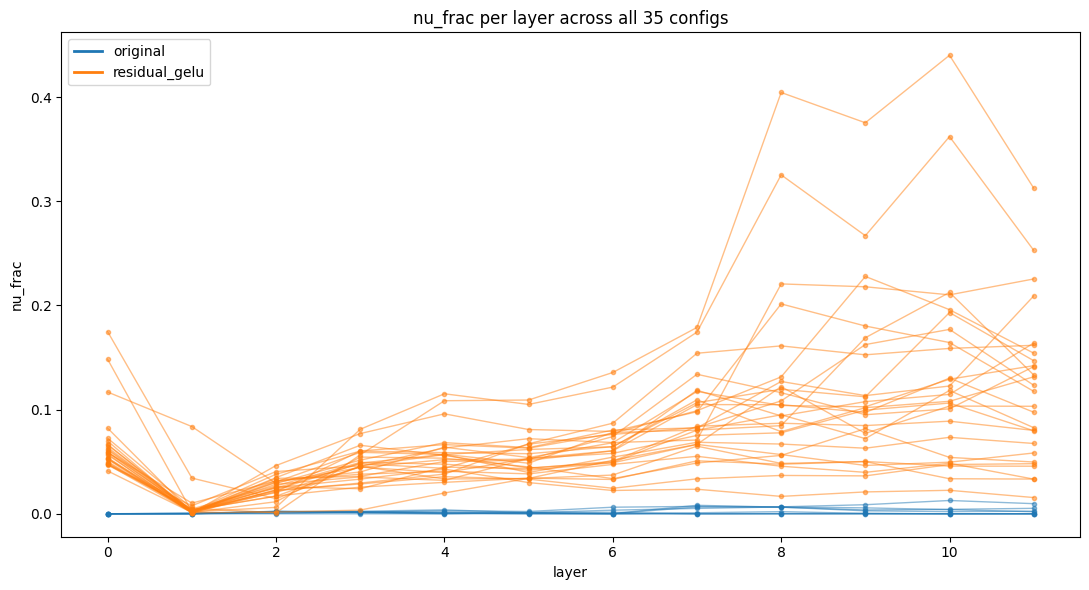

In [12]:
fig, ax = plt.subplots(figsize=(11, 6))

colors = {"original": "tab:blue", "residual_gelu": "tab:orange"}

for name in df_sweep["config"].unique():
    sub = df_sweep[df_sweep["config"] == name]
    qm = sub["query_mode"].iloc[0]
    ax.plot(sub["layer"], sub["nu_frac"], marker="o", markersize=3,
            alpha=0.5, linewidth=1, color=colors.get(qm, "gray"))

# legend proxies
from matplotlib.lines import Line2D
legend_elems = [Line2D([0], [0], color=c, lw=2, label=qm) for qm, c in colors.items()]
ax.legend(handles=legend_elems)

ax.set_xlabel("layer")
ax.set_ylabel("nu_frac")
ax.set_title(f"nu_frac per layer across all {df_sweep['config'].nunique()} configs")
plt.tight_layout()
plt.show()